In [1]:
# !pip install tiktoken

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="tqdm")
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit")   

import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HOME"] = "/scratch/gandhi.gau/hf_cache"
os.environ["HF_HUB_OFFLINE"] = "1"      # use the downloaded model

import re, json, glob, shutil, subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import softmax

from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, set_seed)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

/home/gandhi.gau/.conda/envs/my_gpu_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### GPU Check

In [3]:
import os, socket
print("Host:", socket.gethostname())
print("SLURM job:", os.environ.get("SLURM_JOB_ID"))
print("Partition:", os.environ.get("SLURM_JOB_PARTITION"))
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("torch CUDA build:", torch.version.cuda)

Host: d4053
SLURM job: 11726163
Partition: gpu-short
CUDA_VISIBLE_DEVICES: 0
torch CUDA build: 12.6


In [4]:
# GPU details
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    pr = torch.cuda.get_device_properties(0)
    print("GPU:", pr.name)
    print(f"Memory: {pr.total_memory/1e9:.0f} GB")
    print("Compute capability:", f"{pr.major}.{pr.minor}")
    print("GPUs visible:", torch.cuda.device_count())

print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

CUDA available: True
GPU: NVIDIA H200
Memory: 150 GB
Compute capability: 9.0
GPUs visible: 1
Sun Nov  8 06:37:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.86.15              Driver Version: 570.86.15      CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H200                    On  |   00000000:4C:00.0 Off |                    0 |
| N/A   40C    P0             80W /  700W |       4MiB / 143771MiB |      0%      Default |
|                                         |    

The job runs on an **H200 if one is free, otherwise a V100** (decided by the submit script).

- **H200** supports **bf16**. It has the same range as normal 32-bit numbers, so DeBERTa's loss won't blow up to NaN.
- **V100** doesn't support bf16, so we use **fp16**. It's fast, but DeBERTa can sometimes give a NaN loss with it. The check after the MRPC test run catches this and switches to full 32-bit precision.

The precision used is saved in every result file, so we can report it.

In [5]:
# pick the half-precision type this GPU supports
gpu_name = torch.cuda.get_device_name(0)

# bf16 needs an A100/H100/H200 (compute capability 8.0 or higher); a V100 is 7.0
major, minor = torch.cuda.get_device_capability(0)
if major >= 8:
    PRECISION = "bf16"      # H200 / A100
else:
    PRECISION = "fp16"      # V100

print("Training on:", gpu_name, f"(compute capability {major}.{minor})")
print("Precision:", PRECISION)

Training on: NVIDIA H200 (compute capability 9.0)
Precision: bf16


**Setting up the paths**

DeBERTa gets its own folders, so nothing can overwrite the BERT files. The seeds are the same as BERT's, so the two models can be compared seed by seed.

In [6]:
MODEL_NAME = "microsoft/deberta-v3-base"
SEEDS = [42, 43, 44, 45, 46]
SPLITS = "/home/gandhi.gau/NLP_Project/paraphrase/splits"
OUT = "/scratch/gandhi.gau/paraphrase/out_deberta"
RESULTS = "/home/gandhi.gau/NLP_Project/deberta_results"

for p in (OUT, RESULTS):
    os.makedirs(p, exist_ok=True)

print(sorted(os.listdir(SPLITS)))

['mrpc_dev.csv', 'mrpc_test.csv', 'mrpc_train.csv', 'paws_dev.csv', 'paws_test.csv', 'paws_train.csv', 'qqp_dev.csv', 'qqp_test.csv', 'qqp_train.csv']


### Load cleaned data splits (same as BERT notebook)
These are the CSVs saved by the EDA notebook, so each model sees exactly the same data. `keep_default_na=False` stops pandas from turning text like "NA" or "null" into missing values.

In [7]:
data = {}
for ds in ["mrpc", "qqp", "paws"]:
    data[ds] = {}
    for split in ["train", "dev", "test"]:
        df = pd.read_csv(f"{SPLITS}/{ds}_{split}.csv", keep_default_na=False)
        df["sentence1"] = df["sentence1"].astype(str)
        df["sentence2"] = df["sentence2"].astype(str)
        data[ds][split] = df

In [8]:
expected = {
    "mrpc": {"train": 3301,  "dev": 367,  "test": 408},
    "qqp":  {"train": 36000, "dev": 4000, "test": 5000},
    "paws": {"train": 49259, "dev": 7983, "test": 8000},
}
for ds in data:
    for split, df in data[ds].items():
        n, pct = len(df), df["label"].mean() * 100
        ok = "OK" if n == expected[ds][split] else "MISMATCH"
        print(f"{ds}_{split}: {n} pairs, {pct:.1f}% paraphrase  [{ok}]")
    print("  majority-class test acc:",
          round(max(data[ds]["test"].label.mean(), 1 - data[ds]["test"].label.mean()), 3))

mrpc_train: 3301 pairs, 67.8% paraphrase  [OK]
mrpc_dev: 367 pairs, 64.6% paraphrase  [OK]
mrpc_test: 408 pairs, 68.4% paraphrase  [OK]
  majority-class test acc: 0.684
qqp_train: 36000 pairs, 36.7% paraphrase  [OK]
qqp_dev: 4000 pairs, 35.8% paraphrase  [OK]
qqp_test: 5000 pairs, 36.7% paraphrase  [OK]
  majority-class test acc: 0.633
paws_train: 49259 pairs, 44.1% paraphrase  [OK]
paws_dev: 7983 pairs, 44.2% paraphrase  [OK]
paws_test: 8000 pairs, 44.2% paraphrase  [OK]
  majority-class test acc: 0.558


### Data Leakage Check (Train/Dev/Test Overlap)
(A, B) and (B, A) count as the same pair. All numbers should be 0.

In [9]:
def key(a, b):
    return tuple(sorted([a.lower().strip(), b.lower().strip()]))

def keys(df):
    return [key(a, b) for a, b in zip(df.sentence1, df.sentence2)]

for ds in data:
    tr, dv, te = (set(keys(data[ds][s])) for s in ["train", "dev", "test"])
    print(f"{ds}: train∩test={len(tr & te)}, dev∩test={len(dv & te)}, train∩dev={len(tr & dv)}")

mrpc: train∩test=0, dev∩test=0, train∩dev=0
qqp: train∩test=0, dev∩test=0, train∩dev=0


paws: train∩test=0, dev∩test=0, train∩dev=0


### Loading DeBERTa tokenizer and token length check (same as BERT notebook, model changed)
DeBERTa's tokenizer (SentencePiece) splits words differently from BERT's, so checking token lengths again instead of assuming `max_length=128` would still work 

In [10]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

for ds in data:
    df = data[ds]["train"]
    lens = np.array([len(x) for x in tok(df.sentence1.tolist(), df.sentence2.tolist())["input_ids"]])
    print(f"{ds}: median={np.median(lens):.0f}, p95={np.percentile(lens,95):.0f}, "
          f"p99={np.percentile(lens,99):.0f}, max={lens.max()}, over128={(lens>128).mean()*100:.2f}%")

[transformers] The tokenizer you are loading from 'microsoft/deberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


mrpc: median=51, p95=71, p99=78, max=102, over128=0.00%


qqp: median=26, p95=53, p99=72, max=319, over128=0.03%


paws: median=50, p95=71, p99=79, max=135, over128=0.01%


Looking at the token length distribution and not just the max, we find that for QQP the median is 26 and the 99th percentile is 72, so almost every pair fits well under 128. Only 0.03% of pairs go over, and those get truncated. That is too few to actually affect the results. 

Reason for keeping 128: Match the Bert setup so that the comparison only changes the model and not the preprocessing.

### Checking how DeBERTa sees a sentence pair 
Both sentences go in as **one input**: `[CLS] sentence 1 [SEP] sentence 2 [SEP]`. This lets every word in one sentence attend to every word in the other. The `▁` symbol marks the start of a new word.

In [11]:
# look at how DeBERTa splits one pair into tokens
example = tok("The dog chased the postman.", "The postman chased the dog.")
print(tok.convert_ids_to_tokens(example["input_ids"]))

['[CLS]', '▁The', '▁dog', '▁chased', '▁the', '▁post', 'man', '.', '[SEP]', '▁The', '▁post', 'man', '▁chased', '▁the', '▁dog', '.', '[SEP]']


### Leak guard and tokenization helpers (same as BERT notebook)
The leak guard stops the notebook if any pair appears in 2 splits. `build()` turns each split into token ids and cuts pairs longer than 128 tokens. We do padding later batch by batch.

In [12]:
# Leak guard: runs before any training
for ds in data:
    tr, dv, te = (set(keys(data[ds][s])) for s in ["train", "dev", "test"])
    assert not (tr & te) and not (tr & dv) and not (dv & te), f"LEAK in {ds}"
print("Leak guard passed")

_tok_cache = {}
def get_tok(model_name):
    if model_name not in _tok_cache:
        _tok_cache[model_name] = AutoTokenizer.from_pretrained(model_name)
    return _tok_cache[model_name]

def build(ds, model_name, max_len=128):
    tok = get_tok(model_name)
    out = {}
    for split in ["train", "dev", "test"]:
        df = data[ds][split][["sentence1", "sentence2", "label"]].reset_index(drop=True)
        d = Dataset.from_pandas(df, preserve_index=False)
        d = d.map(lambda b: tok(b["sentence1"], b["sentence2"], truncation=True, max_length=max_len),
                  batched=True, remove_columns=["sentence1", "sentence2"])
        out[split] = d
    return out

Leak guard passed


### Model training and evaluation function (same as BERT notebook, 4 small additions)
Training method, settings and model selection are identical to BERT:
- lr 2e-5, batch 32, 3 epochs, weight decay 0.01, AdamW with linear decay and no warmup (Trainer defaults)
- dev F1 is checked after every epoch, and the*best epoch on dev F1 is kept (`load_best_model_at_end`)
- runs that already finished are skipped, so a stopped job can just be restarted

There are 4 changes from the BERT script, and each one is marked in code:
1. A `precision` option. Using bf16 on the H200 and fp16 on the V100, and fall back to fp32 if fp16 gives trouble.
2. `batch` and `accum` options, only needed if the GPU runs out of memory. A batch of 16 with 2 accumulation steps still gives an effective batch of 32.
3. Extra details in the results file. It now also records the precision and the GPU name, so that we can understand how each number was produced.
4. GPU memory is freed after each run, so back-to-back runs in one job don't run out of memory.

In [13]:
def metrics(p):
    preds = np.argmax(p.predictions, axis=-1)
    y = p.label_ids
    return {"accuracy": accuracy_score(y, preds),
            "precision": precision_score(y, preds, zero_division=0),
            "recall": recall_score(y, preds, zero_division=0),
            "f1": f1_score(y, preds)}

def run(ds, seed=42, model_name="bert-base-uncased", epochs=3, save_model=False, force=False, suffix="",
        precision="fp16", batch=32, accum=1):      # added: precision switch + memory options
    short = model_name.split("/")[-1].split("-")[0]
    tag = f"{short}_{ds}_s{seed}{suffix}"
    result_path = f"{OUT}/{tag}_metrics.json"
    if os.path.exists(result_path) and not force:
        print("Already done:", tag); return json.load(open(result_path))

    set_seed(seed)
    tok = get_tok(model_name)
    d = build(ds, model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    model = model.float()   # DeBERTa-v3 weights are stored in fp16, so train with fp32 weights

    args = TrainingArguments(
        output_dir=f"{OUT}/{tag}", learning_rate=2e-5,
        per_device_train_batch_size=batch,              # changed: was 32 (still 32 by default)
        gradient_accumulation_steps=accum,              # added: batch 16 x accum 2 = 32 if memory runs out
        per_device_eval_batch_size=64,
        num_train_epochs=epochs, weight_decay=0.01, seed=seed,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        save_only_model=True, load_best_model_at_end=True, metric_for_best_model="f1",
        logging_steps=50,
        fp16=(precision == "fp16"),                     # changed: V100 half precision
        bf16=(precision == "bf16"),                     # added: H200 half precision
        report_to="none")

    trainer = Trainer(model=model, args=args, train_dataset=d["train"], eval_dataset=d["dev"],
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()

    dev_curve = [{"epoch": h["epoch"], "dev_f1": h["eval_f1"], "dev_loss": h["eval_loss"]}
                 for h in trainer.state.log_history if "eval_f1" in h]

    out = trainer.predict(d["test"])
    preds = np.argmax(out.predictions, -1)
    y = np.array(data[ds]["test"]["label"])
    assert len(preds) == len(y)

    np.save(f"{OUT}/{tag}_test_preds.npy", preds)
    np.save(f"{OUT}/{tag}_test_logits.npy", out.predictions)

    res = {"tag": tag, "model": model_name, "dataset": ds, "seed": seed,
           "precision": precision, "gpu": torch.cuda.get_device_name(0),   # added: record how it was trained
           "n_train": len(d["train"]), "n_test": len(y),
           "test_accuracy": float(accuracy_score(y, preds)),
           "test_precision": float(precision_score(y, preds, zero_division=0)),
           "test_recall": float(recall_score(y, preds, zero_division=0)),
           "test_f1": float(f1_score(y, preds)),
           "majority_acc": float(max(y.mean(), 1 - y.mean())),
           "frac_pred_paraphrase": float(preds.mean()),
           "dev_curve": dev_curve}
    # save the model first, then the results file (the results file is what marks a run as done)
    if save_model:
        trainer.save_model(f"{OUT}/{tag}/best")
    json.dump(res, open(result_path, "w"), indent=2)
    for ck in glob.glob(f"{OUT}/{tag}/checkpoint-*"):
        shutil.rmtree(ck, ignore_errors=True)

    for f in glob.glob(f"{OUT}/{tag}_*.npy") + [result_path]:
        shutil.copy(f, RESULTS)

    # added: free GPU memory before the next run (15 runs in one notebook)
    del model, trainer
    torch.cuda.empty_cache()

    print(tag, {k: round(v, 4) for k, v in res.items() if k.startswith("test_")})
    return res

We used AutoModelForSequenceClassification, which adds a pooler and a linear classification head on top of the pretrained encoder. The head starts with random weights. 
Also, full finetuning was performed, no layers were frozen so that the encoder and head are trained together for 3 epochs at learning rate 2e-5. 

### Test run on MRPC, seed 42 (same call as BERT notebook)
MRPC is small and trains in a few minutes, so it's a cheap check before the long runs.

In [14]:
r = run("mrpc", seed=42, model_name=MODEL_NAME, save_model=True, precision=PRECISION)

Already done: deberta_mrpc_s42


### Checking that training worked 
The job runs on its own, so this cell checks the MRPC run automatically. Training is broken if:
- the dev loss is NaN, which half precision can cause with DeBERTa, or
- the model predicts only one class for every pair.

If either happens, MRPC is retrained in full fp32, and fp32 is used for all the other runs.

In [15]:
# if the job was restarted, use the precision the MRPC run actually used
PRECISION = r["precision"]

# print dev F1 and loss after each epoch
print("Dev results after each epoch:")
for c in r["dev_curve"]:
    print("  epoch", c["epoch"], " dev F1 =", round(c["dev_f1"], 4), " dev loss =", round(c["dev_loss"], 4))

# sign 1: the loss became NaN
nan_found = False
for c in r["dev_curve"]:
    if np.isnan(c["dev_loss"]):
        nan_found = True

# sign 2: the model predicts the same class for everything
pred_share = r["frac_pred_paraphrase"]
one_class = (pred_share == 0.0) or (pred_share == 1.0)

if nan_found or one_class:
    print("\nTraining looks broken with", PRECISION, "-> switching to full fp32")
    PRECISION = "fp32"
    r = run("mrpc", seed=42, model_name=MODEL_NAME, save_model=True, precision=PRECISION, force=True)
else:
    print("\nTraining looks fine with", PRECISION)
    print("Share of MRPC test pairs predicted as paraphrase:", round(pred_share, 3))

Dev results after each epoch:
  epoch 1.0  dev F1 = 0.8903  dev loss = 0.3871
  epoch 2.0  dev F1 = 0.9139  dev loss = 0.2732
  epoch 3.0  dev F1 = 0.9133  dev loss = 0.2648

Training looks fine with fp16
Share of MRPC test pairs predicted as paraphrase: 0.64


### Training all models, 3 datasets × 5 seeds (same loop as BERT notebook)
Every model is saved on its first run. (The BERT notebook saved only the QQP models and then trained MRPC and PAWS a second time to save them, but saving once gives the same results and saves hours.)

If the job stops because of the time limit, we just submit it again and finished runs are skipped.

In [16]:
for ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        run(ds, seed=s, model_name=MODEL_NAME, save_model=True, precision=PRECISION)

Already done: deberta_mrpc_s42
Already done: deberta_mrpc_s43
Already done: deberta_mrpc_s44
Already done: deberta_mrpc_s45
Already done: deberta_mrpc_s46
Already done: deberta_qqp_s42
Already done: deberta_qqp_s43
Already done: deberta_qqp_s44
Already done: deberta_qqp_s45
Already done: deberta_qqp_s46
Already done: deberta_paws_s42
Already done: deberta_paws_s43
Already done: deberta_paws_s44
Already done: deberta_paws_s45
Already done: deberta_paws_s46


### DeBERTa results table (same as BERT notebook, file names changed)
We have the mean ± standard deviation over the 5 seeds. `ddof=1` gives sample standard deviation, which is correct for a small number of runs.

In [8]:
rows = []
for ds in ["mrpc", "qqp", "paws"]:
    rs = [json.load(open(f"{OUT}/deberta_{ds}_s{s}_metrics.json")) for s in SEEDS]
    row = {"dataset": ds, "majority_acc": round(rs[0]["majority_acc"], 3)}
    for m in ["accuracy", "precision", "recall", "f1"]:
        v = np.array([x[f"test_{m}"] for x in rs])
        row[m] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(f"{RESULTS}/deberta_summary.csv", index=False)
summary

,dataset,majority_acc,accuracy,precision,recall,f1
0,mrpc,0.684,0.880 ± 0.006,0.912 ± 0.019,0.913 ± 0.021,0.912 ± 0.004
1,qqp,0.633,0.885 ± 0.002,0.820 ± 0.016,0.882 ± 0.021,0.849 ± 0.002
2,paws,0.558,0.948 ± 0.001,0.931 ± 0.005,0.954 ± 0.004,0.942 ± 0.001


### Dev F1 for choosing between BERT and DeBERTa 
The winner is chosen based on the dev F1, never on the test set. The test set is only for the final scores, so we do not use it to make any choices. The table above only has test scores, so here we collect the best dev F1 of each run. 

In [9]:
dev_rows = []
for ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        res = json.load(open(f"{OUT}/deberta_{ds}_s{s}_metrics.json"))

        # best dev F1 over the 3 epochs (this is the epoch that was kept)
        best = 0
        for c in res["dev_curve"]:
            if c["dev_f1"] > best:
                best = c["dev_f1"]

        dev_rows.append({"dataset": ds, "seed": s, "best_dev_f1": best, "precision": res["precision"]})

dev_df = pd.DataFrame(dev_rows)
dev_df.to_csv(f"{RESULTS}/deberta_dev_f1.csv", index=False)

# mean and std over the 5 seeds for each dataset
dev_df.groupby("dataset")["best_dev_f1"].agg(["mean", "std"]).round(3)

,mean,std
dataset,,
mrpc,0.912,0.004
paws,0.951,0.002
qqp,0.844,0.004


### PAWS accuracy by word overlap (same as BERT notebook, "bert" -> "deberta")
Does DeBERTa get the hardest PAWS pairs right, where both sentences have exactly the same words in a different order? 
A bag-of-words model like our TF-IDF baseline cannot tell these pairs apart at all, since it only sees which words appear. So if DeBERTa gets them right, it must be using word order and not just counting shared words.

In [10]:
te = data["paws"]["test"].copy()
bag = lambda s: tuple(sorted(re.findall(r"\w+", s.lower())))
jac = lambda a, b: len(set(re.findall(r"\w+", a.lower())) & set(re.findall(r"\w+", b.lower()))) / \
                   max(1, len(set(re.findall(r"\w+", a.lower())) | set(re.findall(r"\w+", b.lower()))))

te["same_bag"] = [bag(a) == bag(b) for a, b in zip(te.sentence1, te.sentence2)]
te["jac"] = [jac(a, b) for a, b in zip(te.sentence1, te.sentence2)]
te["bucket"] = pd.cut(te.jac, [0, .7, .8, .9, .99, 1.0], include_lowest=True)

# fraction of seeds that got each test row right
te["deberta_correct"] = np.mean([np.load(f"{OUT}/deberta_paws_s{s}_test_preds.npy") == te.label.values
                                 for s in SEEDS], axis=0)

print("Same words, different order (bag-of-words can't separate these):")
print(te.groupby("same_bag").agg(n=("label", "size"), pct_para=("label", "mean"),
                                 deberta_acc=("deberta_correct", "mean")).round(3), "\n")
print(te.groupby("bucket", observed=True).agg(n=("label", "size"), pct_para=("label", "mean"),
                                              deberta_acc=("deberta_correct", "mean")).round(3), "\n")

# dev vs test, per seed
for s in SEEDS:
    r = json.load(open(f"{OUT}/deberta_paws_s{s}_metrics.json"))
    print(s, "best dev F1:", round(max(c["dev_f1"] for c in r["dev_curve"]), 3),
          "| test F1:", round(r["test_f1"], 3))

Same words, different order (bag-of-words can't separate these):
             n  pct_para  deberta_acc
same_bag                             
False     7147     0.459        0.948
True       853     0.298        0.955 

                  n  pct_para  deberta_acc
bucket                                    
(-0.001, 0.7]    26     0.077        0.985
(0.7, 0.8]      545     0.319        0.938
(0.8, 0.9]     4020     0.470        0.943
(0.9, 0.99]    1965     0.470        0.955
(0.99, 1.0]    1444     0.377        0.957 

42 best dev F1: 0.952 | test F1: 0.942
43 best dev F1: 0.948 | test F1: 0.942
44 best dev F1: 0.951 | test F1: 0.942
45 best dev F1: 0.951 | test F1: 0.943
46 best dev F1: 0.954 | test F1: 0.943


## Cross dataset testing
### QQP -> PAWS, 5 seeds (same as BERT notebook, names changed)
The QQP-trained models are tested on PAWS with no retraining. If a model learned the shortcut "lots of shared words = paraphrase" from QQP, it will call most PAWS pairs paraphrases. We can see this when `frac_pred_para` (the share of pairs it calls paraphrases) is high and `specificity` (the share of real non-paraphrases it gets correct) is low. For comparison, BERT got 0.485 accuracy here.

In [17]:
mn = MODEL_NAME
tok = get_tok(mn)
dp = build("paws", mn)
y = data["paws"]["test"]["label"].values

rows = []
for s in SEEDS:
    model = AutoModelForSequenceClassification.from_pretrained(f"{OUT}/deberta_qqp_s{s}/best")
    tr = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                 args=TrainingArguments(output_dir=f"{OUT}/tmp", per_device_eval_batch_size=64,
                                        fp16=(PRECISION == "fp16"), bf16=(PRECISION == "bf16"), report_to="none"))
    out = tr.predict(dp["test"])
    p = np.argmax(out.predictions, -1)
    np.save(f"{OUT}/deberta_qqp_on_paws_s{s}_test_preds.npy", p)
    np.save(f"{OUT}/deberta_qqp_on_paws_s{s}_test_logits.npy", out.predictions)
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    rows.append({"seed": s, "acc": accuracy_score(y, p), "f1": f1_score(y, p),
                 "frac_pred_para": p.mean(), "recall": tp/(tp+fn), "specificity": tn/(tn+fp),
                 "TN": tn, "FP": fp, "FN": fn, "TP": tp})

cross = pd.DataFrame(rows).round(3)
display(cross)
print(cross[["acc", "f1", "frac_pred_para", "recall", "specificity"]].agg(["mean", "std"]).round(3))

for f in glob.glob(f"{OUT}/deberta_qqp_on_paws_*.npy"):
    shutil.copy(f, RESULTS)

[transformers] The tokenizer you are loading from 'microsoft/deberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.



Map:   0%|          | 0/49259 [00:00<?, ? examples/s]


Map:   2%|▏         | 1000/49259 [00:00<00:06, 7861.75 examples/s]


Map:   4%|▍         | 2000/49259 [00:00<00:05, 8816.75 examples/s]


Map:   6%|▌         | 3000/49259 [00:00<00:05, 8899.53 examples/s]


Map:   8%|▊         | 4000/49259 [00:00<00:05, 8895.16 examples/s]

... (74 outputs left out)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10037.91it/s]

,seed,acc,f1,frac_pred_para,recall,specificity,TN,FP,FN,TP
0,42,0.460,0.614,0.957,0.971,0.055,245,4219,101,3435
1,43,0.574,0.660,0.812,0.937,0.286,1278,3186,222,3314
2,44,0.514,0.632,0.878,0.943,0.174,778,3686,202,3334
3,45,0.544,0.651,0.866,0.964,0.211,941,3523,129,3407
4,46,0.527,0.640,0.871,0.950,0.192,857,3607,178,3358


        acc     f1  frac_pred_para  recall  specificity
mean  0.524  0.639           0.877   0.953        0.184
std   0.042  0.018           0.052   0.014        0.084


## Full transfer matrix: train on one dataset, test on all three (same as BERT notebook, names changed)
Every trained model is tested on every test set, with no retraining. That’s 3 train sets × 5 seeds × 3 test sets, 45 evaluations.

In [18]:
def model_dir(train_ds, s):
    return f"{OUT}/deberta_{train_ds}_s{s}/best"

mn = MODEL_NAME
tok = get_tok(mn)
built = {ds: build(ds, mn) for ds in ["mrpc", "qqp", "paws"]}

rows = []
for train_ds in ["mrpc", "qqp", "paws"]:
    for s in SEEDS:
        model = AutoModelForSequenceClassification.from_pretrained(model_dir(train_ds, s))
        tr = Trainer(model=model, data_collator=DataCollatorWithPadding(tok),
                     args=TrainingArguments(output_dir=f"{OUT}/tmp", per_device_eval_batch_size=64,
                                            fp16=(PRECISION == "fp16"), bf16=(PRECISION == "bf16"), report_to="none"))
        for test_ds in ["mrpc", "qqp", "paws"]:
            out = tr.predict(built[test_ds]["test"])
            y = data[test_ds]["test"]["label"].values
            p = np.argmax(out.predictions, -1)
            prob = softmax(out.predictions, axis=-1)[:, 1]
            np.save(f"{OUT}/deberta_xfer_{train_ds}_on_{test_ds}_s{s}_preds.npy", p)
            np.save(f"{OUT}/deberta_xfer_{train_ds}_on_{test_ds}_s{s}_logits.npy", out.predictions)
            rows.append({"train": train_ds, "test": test_ds, "seed": s,
                         "acc": accuracy_score(y, p), "f1": f1_score(y, p),
                         "auc": roc_auc_score(y, prob), "frac_pred_para": p.mean(),
                         "majority_acc": max(y.mean(), 1 - y.mean())})
        del model, tr
        torch.cuda.empty_cache()

xfer = pd.DataFrame(rows)
xfer.to_csv(f"{RESULTS}/deberta_transfer_all_runs.csv", index=False)
for f in glob.glob(f"{OUT}/deberta_xfer_*.npy"):
    shutil.copy(f, RESULTS)

def ms(x): return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}"
for m in ["acc", "auc", "frac_pred_para"]:
    print(f"\n{m} (rows = trained on, cols = tested on)")
    display(xfer.pivot_table(index="train", columns="test", values=m, aggfunc=ms))
print("\nmajority accuracy per test set:")
print(xfer.groupby("test").majority_acc.first().round(3))


Map:   0%|          | 0/3301 [00:00<?, ? examples/s]


Map:  30%|███       | 1000/3301 [00:00<00:00, 6905.49 examples/s]


Map:  61%|██████    | 2000/3301 [00:00<00:00, 7835.25 examples/s]


Map:  91%|█████████ | 3000/3301 [00:00<00:00, 8033.99 examples/s]


Map: 100%|██████████| 3301/3301 [00:00<00:00, 7836.52 examples/s]


Map:   0%|          | 0/367 [00:00<?, ? examples/s]

... (130 outputs left out)

test,mrpc,paws,qqp
train,,,
mrpc,0.934 ± 0.003,0.502 ± 0.035,0.763 ± 0.015
paws,0.773 ± 0.011,0.985 ± 0.001,0.832 ± 0.002
qqp,0.750 ± 0.022,0.731 ± 0.053,0.953 ± 0.001



frac_pred_para (rows = trained on, cols = tested on)


test,mrpc,paws,qqp
train,,,
mrpc,0.685 ± 0.029,0.999 ± 0.001,0.476 ± 0.034
paws,0.769 ± 0.037,0.453 ± 0.004,0.479 ± 0.046
qqp,0.811 ± 0.026,0.877 ± 0.052,0.395 ± 0.017



majority accuracy per test set:
test
mrpc    0.684
paws    0.558
qqp     0.633
Name: majority_acc, dtype: float64


### Testing all 3 models on hand-written, new test cases (same as BERT notebook, names changed)
Same 6 pairs and same seed (44) as the BERT notebook, so the predictions can be compared directly. The swapped-role pairs are mini PAWS tests.

In [19]:
def load(train_ds, s=44):
    d = f"{OUT}/deberta_{train_ds}_s{s}/best"
    m = AutoModelForSequenceClassification.from_pretrained(d).eval()
    return m.cuda() if torch.cuda.is_available() else m

models_demo = {ds: load(ds) for ds in ["mrpc", "qqp", "paws"]}
tok = get_tok(MODEL_NAME)

def predict(s1, s2):
    enc = tok(s1, s2, return_tensors="pt", truncation=True, max_length=128)
    enc = {k: v.to(next(iter(models_demo.values())).device) for k, v in enc.items()}
    row = {}
    for name, m in models_demo.items():
        with torch.no_grad():
            p = softmax(m(**enc).logits.cpu().numpy(), axis=-1)[0, 1]
        row[name + "_model"] = f"{p:.2f}"
    return row

pairs = [
    #(sentence1, sentence2, what we expect)
    ("The cat sat on the mat.", "A cat was sitting on the mat.", "paraphrase"),
    ("The dog chased the postman.", "The postman chased the dog.", "NOT (swapped roles)"),
    ("How do I learn Python quickly?", "What is the fastest way to learn Python?", "paraphrase"),
    ("She gave the book to him.", "He gave the book to her.", "NOT (swapped roles)"),
    ("The company reported record profits in 2025.", "The firm posted its highest ever earnings last year.", "paraphrase"),
    ("I love pizza.", "The stock market closed lower today.", "NOT (unrelated)"),
]

rows = []
for a, b, exp in pairs:
    rows.append({"s1": a, "s2": b, "expected": exp, **predict(a, b)})
pd.set_option("display.max_colwidth", 60)
pd.DataFrame(rows)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10703.13it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 10336.22it/s]


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 202/202 [00:00<00:00, 9771.75it/s]

,s1,s2,expected,mrpc_model,qqp_model,paws_model
0,The cat sat on the mat.,A cat was sitting on the mat.,paraphrase,0.98,0.99,0.99
1,The dog chased the postman.,The postman chased the dog.,NOT (swapped roles),0.98,0.66,0.00
2,How do I learn Python quickly?,What is the fastest way to learn Python?,paraphrase,0.89,0.94,0.99
3,She gave the book to him.,He gave the book to her.,NOT (swapped roles),0.98,0.01,0.00
4,The company reported record profits in 2025.,The firm posted its highest ever earnings last year.,paraphrase,0.88,0.00,0.40
5,I love pizza.,The stock market closed lower today.,NOT (unrelated),0.24,0.00,0.44


## Visualizing the results (same as BERT notebook, titles and names changed)

In [11]:
FIG = f"{RESULTS}/figures"; os.makedirs(FIG, exist_ok=True)
order = ["mrpc", "qqp", "paws"]
y_paws = data["paws"]["test"]["label"].values

### Transfer matrix heatmap

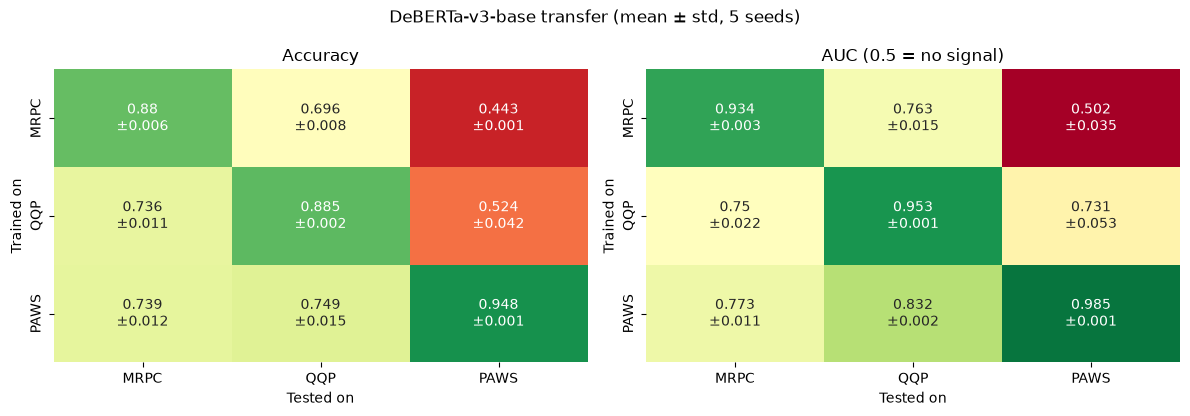

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, m, title, lo in [(ax[0], "acc", "Accuracy", 0.4), (ax[1], "auc", "AUC (0.5 = no signal)", 0.5)]:
    mean = xfer.pivot_table(index="train", columns="test", values=m).loc[order, order]
    std = xfer.pivot_table(index="train", columns="test", values=m, aggfunc=lambda x: x.std(ddof=1)).loc[order, order]
    annot = mean.round(3).astype(str) + "\n±" + std.round(3).astype(str)
    sns.heatmap(mean, annot=annot, fmt="", cmap="RdYlGn", vmin=lo, vmax=1, cbar=False, ax=a,
                xticklabels=[o.upper() for o in order], yticklabels=[o.upper() for o in order])
    a.set_title(title); a.set_xlabel("Tested on"); a.set_ylabel("Trained on")
plt.suptitle("DeBERTa-v3-base transfer (mean ± std, 5 seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/1_transfer_heatmaps.png", dpi=200); plt.show()

### Histograms of predicted P(paraphrase) on PAWS. Score Distributions on PAWS

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# added: load the saved DeBERTa results so the notebook doesn't need to be rerun
EXPORT = "D:/Dummy/NLP_Project/deberta_export"
FIG = f"{EXPORT}/figures"
xfer = pd.read_csv(f"{EXPORT}/deberta_transfer_all_runs.csv")

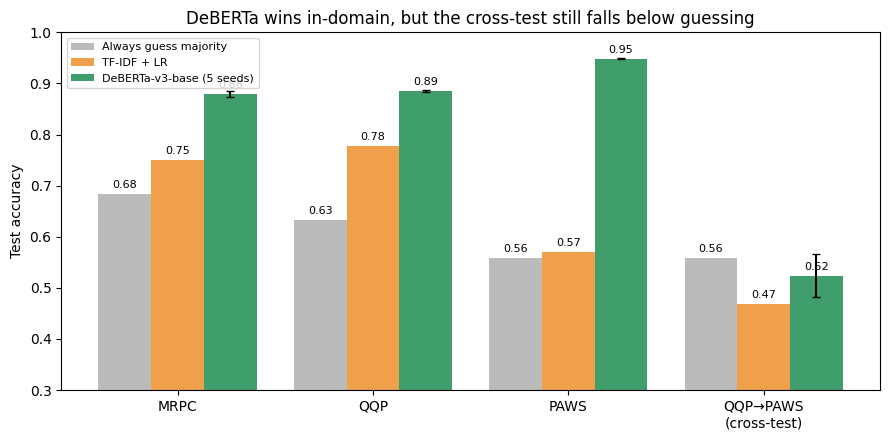

In [2]:
def g(tr, te):
    # mean and std of DeBERTa's accuracy over the 5 seeds
    v = xfer[(xfer.train == tr) & (xfer.test == te)].acc
    return v.mean(), v.std(ddof=1)

pairs = [("mrpc", "mrpc"), ("qqp", "qqp"), ("paws", "paws"), ("qqp", "paws")]
labels = ["MRPC", "QQP", "PAWS", "QQP→PAWS\n(cross-test)"]
deb = [g(*p) for p in pairs]
base = [0.750, 0.778, 0.570, 0.469]        # from my results_baseline.csv
maj  = [0.684, 0.633, 0.558, 0.558]        # always guessing the most common label

x = np.arange(4); w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, maj, w, label="Always guess majority", color="#bbbbbb")
ax.bar(x, base, w, label="TF-IDF + LR", color="#f0a04b")
ax.bar(x + w, [d[0] for d in deb], w, yerr=[d[1] for d in deb], capsize=3, label="DeBERTa-v3-base (5 seeds)", color="#3f9e6b")

# write the value on top of each bar
for xs, vals in [(x - w, maj), (x, base), (x + w, [d[0] for d in deb])]:
    for xi, v in zip(xs, vals): ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0.3, 1.0); ax.set_ylabel("Test accuracy")
ax.set_title("DeBERTa wins in-domain, but the cross-test still falls below guessing")
ax.legend(loc="upper left", fontsize=8); plt.tight_layout()
plt.savefig(f"{FIG}/5_deberta_vs_baseline.png", dpi=200); plt.show()

### ROC curves on PAWS
A curve close to the dashed diagonal means the model cannot separate the two classes.

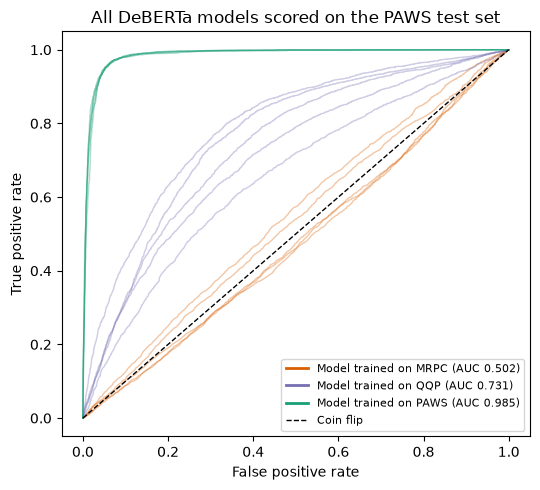

In [13]:
colors = {"mrpc": "#d95f02", "qqp": "#7570b3", "paws": "#1b9e77"}
fig, ax = plt.subplots(figsize=(5.5, 5))
for tr in order:
    aucs = []
    for s in SEEDS:
        lg = np.load(f"{OUT}/deberta_xfer_{tr}_on_paws_s{s}_logits.npy")
        pr = softmax(lg, axis=-1)[:, 1]
        fpr, tpr, _ = roc_curve(y_paws, pr)
        aucs.append(xfer[(xfer.train == tr) & (xfer.test == "paws") & (xfer.seed == s)].auc.iloc[0])
        ax.plot(fpr, tpr, color=colors[tr], alpha=0.35, lw=1)
    ax.plot([], [], color=colors[tr], lw=2, label=f"Model trained on {tr.upper()} (AUC {np.mean(aucs):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Coin flip")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("All DeBERTa models scored on the PAWS test set")
ax.legend(fontsize=8)   # added: so the labels show
plt.tight_layout(); plt.savefig(f"{FIG}/3_roc_on_paws.png", dpi=200); plt.show()

### PAWS confusion matrices by training dataset
Percentage of each true class, averaged over the 5 seeds. This shows how each model fails, eg: by calling most non-paraphrases "paraphrase."

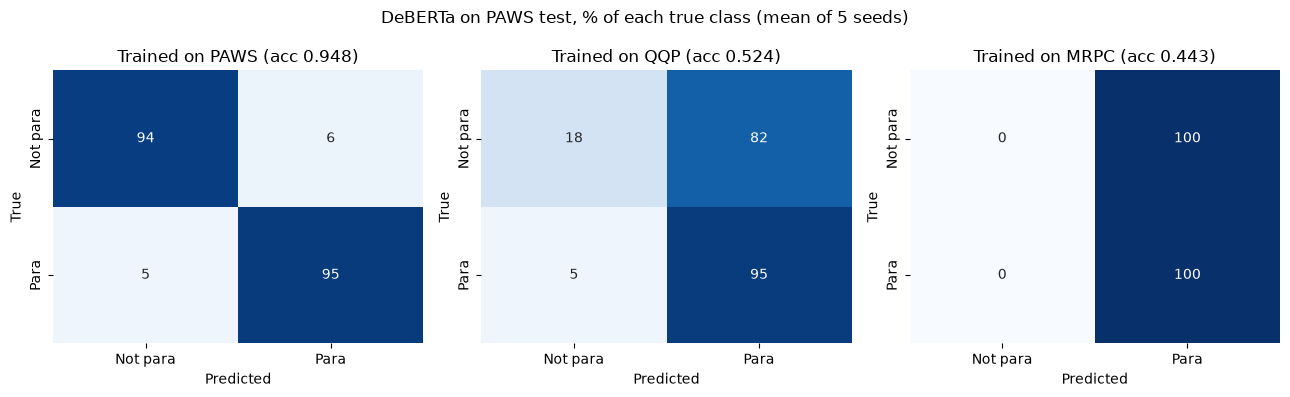

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, tr in zip(ax, ["paws", "qqp", "mrpc"]):
    cms = np.mean([confusion_matrix(y_paws, np.load(f"{OUT}/deberta_xfer_{tr}_on_paws_s{s}_preds.npy"), normalize="true")
                   for s in SEEDS], axis=0) * 100
    acc = xfer[(xfer.train == tr) & (xfer.test == "paws")].acc.mean()
    sns.heatmap(cms, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=a,
                xticklabels=["Not para", "Para"], yticklabels=["Not para", "Para"])
    a.set_title(f"Trained on {tr.upper()} (acc {acc:.3f})"); a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.suptitle("DeBERTa on PAWS test, % of each true class (mean of 5 seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/4_confusion_paws.png", dpi=200); plt.show()

### Exporting files for the final comparison (same as BERT notebook, names and paths changed)
Same format as the BERT export.

In [15]:
SRC = OUT if os.path.exists(f"{OUT}/deberta_xfer_qqp_on_paws_s42_logits.npy") else RESULTS
print("reading logits from:", SRC)

EXPORT = "/home/gandhi.gau/NLP_Project/deberta_export"
os.makedirs(f"{EXPORT}/preds", exist_ok=True); os.makedirs(f"{EXPORT}/figures", exist_ok=True)

for tr in order:
    for te in order:
        df = data[te]["test"][["sentence1", "sentence2", "label"]].copy()
        probs = np.stack([softmax(np.load(f"{SRC}/deberta_xfer_{tr}_on_{te}_s{s}_logits.npy"), axis=-1)[:, 1]
                          for s in SEEDS])
        assert probs.shape[1] == len(df)
        df["prob"] = probs.mean(0).round(4)
        df["pred"] = (df["prob"] > 0.5).astype(int)
        for s, p in zip(SEEDS, probs):
            df[f"pred_s{s}"] = (p > 0.5).astype(int)
        df = df[["sentence1", "sentence2", "label", "pred", "prob"] + [f"pred_s{s}" for s in SEEDS]]
        df.to_csv(f"{EXPORT}/preds/deberta_{tr}_to_{te}.csv", index=False)

reading logits from: /scratch/gandhi.gau/paraphrase/out_deberta


In [16]:
# copy the figures and result tables into the export folder
for f in glob.glob(f"{FIG}/*.png"):
    shutil.copy(f, f"{EXPORT}/figures/")
for name in ["deberta_summary.csv", "deberta_transfer_all_runs.csv", "deberta_dev_f1.csv"]:
    shutil.copy(f"{RESULTS}/{name}", EXPORT)
print("Export ready:", EXPORT)

Export ready: /home/gandhi.gau/NLP_Project/deberta_export


## Conclusion

**DeBERTa learns each dataset very well:** When trained and tested on the same dataset, DeBERTa-v3-base gets 0.880 accuracy on MRPC, 0.885 on QQP and 0.948 on PAWS (averaged over 5 seeds). All of these are well above the majority-class guess (0.684, 0.633 and 0.558), and the results barely change between seeds (for example PAWS 0.948 ± 0.001), so they are reliable.

**When trained on PAWS, it actually pays attention to word order:** To test whether the model relies on lexical overlap alone, we evaluated it on the 853 PAWS test pairs whose 2 sentences contain the same set of words. A bag-of-words representation maps both sentences of each such pair to the same vector, so no classifier built on it can tell paraphrases from non-paraphrases within this subset. The PAWS-trained DeBERTa model still classifies 95.5% of these pairs correctly. This indicates that it encodes word order and syntactic structure, not just lexical overlap. Our hand-constructed examples support this conclusion: for the pair “The dog chased the postman” or “The postman chased the dog,” the model gives a paraphrase probability of 0.00 (rounded).

**However, the knowledge learned from QQP does not transfer to PAWS:** The QQP-trained model reaches only 0.524 ± 0.042 accuracy on PAWS, which is below the majority-class baseline of 0.558. 87.7% of PAWS pairs are labelled as parapharses and 18.4% of the true non-paraphrases are correctly identified. This pattern fits the shortcut that we had indentified in our EDA notebook, that in QQP a higher lexical overlap is a strong indentification for the paraphrase label and the model happens to have learnt to rely on that particular clue. The MRPC-trained model transfers even worse. For the 99.9% of PAWS pairs it predicts the label as paraphrase, and its AUC of 0.502 shows that it has essentially no ability to discriminate between the two classes.

**There is a small hint of real understanding, though.** Even though the QQP model's accuracy on PAWS is poor, its AUC there is 0.731, well above 0.5. In other words, the model usually gives true paraphrases a higher score than non-paraphrases, so its scores carry useful information. The low accuracy comes from the decision threshold i.e. at the default cut-off of 0.5, the model labels too many pairs as paraphrases. This suggests that the model learned some meaning from QQP, but not enough to stop it from relying on word overlap.

**Models trained on more challenging data generalize better:** The PAWS-trained models do best outside their own dataset (0.749 on QQP and 0.739 on MRPC, both above the majority guess), while the QQP and MRPC models fall apart on PAWS. This suggests that training on difficult pairs, where word overlap does not reveal the label, teaches a more general skill than training on data where overlap mostly gives the answer away.



**What this means for the project** 
A stronger model on its own is not enough. DeBERTa scores very well in-domain, but it still learns whatever shortcuts its training data allows. This is the main motivation for the debiasing experiment in which we train on QQP while down-weighting the pairs that word overlap alone already classifies correctly. 